In [ ]:
'''Calculate and interpret key classification metrics such as precision, recall, F1-score, and 
balanced accuracy to assess the performance of admission prediction models across diverse applicant groups.'''

In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix

In [2]:
# load dataset and inspect structure
df = pd.read_csv('Adm.csv')
print('dataset dimensions:', df.shape)
print('\nmissing values count:\n', df.isnull().sum())
print('\nsummary statistics:\n', df.describe())
df.head()

dataset dimensions: (1000, 12)

missing values count:
 Serial No.              0
GRE Score               0
TOEFL Score             0
University Rating       0
SOP                     0
LOR                     0
CGPA                    0
Research                0
Chance of Admit         0
Application_DateTime    0
University_Name         0
region                  0
dtype: int64

summary statistics:
         Serial No.    GRE Score  TOEFL Score  University Rating          SOP  \
count  1000.000000  1000.000000  1000.000000        1000.000000  1000.000000   
mean    500.500000   315.965000   106.564000           3.015000     3.393500   
std     288.819436    13.415653     7.634277           1.317768     1.027279   
min       1.000000   290.000000    92.000000           1.000000     0.900000   
25%     250.750000   305.000000   101.000000           2.000000     2.500000   
50%     500.500000   316.000000   107.000000           3.000000     3.500000   
75%     750.250000   326.250000   113.

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# define target variable and inspect class balance
admission_threshold = 0.70
df['Admitted'] = (df['Chance of Admit'] >= admission_threshold).astype(int)

class_counts = df['Admitted'].value_counts()
class_percentages = df['Admitted'].value_counts(normalize=True) * 100

print('target class counts:\n', class_counts)
print('\ntarget class proportions (%):\n', class_percentages)

target class counts:
 Admitted
1    594
0    406
Name: count, dtype: int64

target class proportions (%):
 Admitted
1    59.4
0    40.6
Name: proportion, dtype: float64


In [4]:
# inspect diverse applicant groups across dataset
region_summary = df.groupby('region').agg(
    total_applicants=('Serial No.', 'count'),
    admitted_count=('Admitted', 'sum'),
    admission_rate=('Admitted', 'mean'),
    avg_gre=('GRE Score', 'mean'),
    avg_cgpa=('CGPA', 'mean')
).reset_index()
region_summary['admission_rate'] = round(region_summary['admission_rate'] * 100, 2)
region_summary['avg_gre'] = round(region_summary['avg_gre'], 2)
region_summary['avg_cgpa'] = round(region_summary['avg_cgpa'], 2)
region_summary

,region,total_applicants,admitted_count,admission_rate,avg_gre,avg_cgpa
0,Central,26,14,53.85,318.62,8.62
1,East,115,69,60.00,316.43,8.56
2,North,305,167,54.75,315.75,8.62
3,Northeast,25,17,68.00,313.72,8.67
4,South,379,224,59.10,316.37,8.56
5,West,150,103,68.67,314.93,8.60


In [5]:
# prepare features and split train test sets
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Admitted']
groups_region = df['region']
groups_research = df['Research']

X_train, X_test, y_train, y_test, reg_train, reg_test, res_train, res_test = train_test_split(
    X, y, groups_region, groups_research, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
# train multiple admission prediction models
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [7]:
# define and calculate key classification metrics
def compute_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = f1_score(y_true, y_pred, zero_division=0)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    return {
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'specificity': round(spec, 4),
        'f1_score': round(f1, 4),
        'balanced_accuracy': round(bal_acc, 4)
    }

models_comparison = pd.DataFrame([
    {'model': 'logistic regression', **compute_metrics(y_test, y_pred_lr)},
    {'model': 'random forest', **compute_metrics(y_test, y_pred_rf)}
])
models_comparison

,model,accuracy,precision,recall,specificity,f1_score,balanced_accuracy
0,logistic regression,0.655,0.6923,0.7563,0.5062,0.7229,0.6312
1,random forest,0.620,0.6807,0.6807,0.5309,0.6807,0.6058


In [8]:
# interpret key classification metrics in admission context
lr_metrics = compute_metrics(y_test, y_pred_lr)
print('--- classification metrics interpretation in admission prediction ---')
print('1. precision (' + str(lr_metrics['precision']) + '):')
print('   represents the percentage of admitted applicants who truly meet the criteria.')
print('   high precision prevents granting admission to unqualified candidates.\n')
print('2. recall / sensitivity (' + str(lr_metrics['recall']) + '):')
print('   represents the percentage of all qualified applicants who were granted admission.')
print('   high recall prevents unjust rejections of deserving applicants.\n')
print('3. f1-score (' + str(lr_metrics['f1_score']) + '):')
print('   harmonic mean of precision and recall providing balanced evaluation.\n')
print('4. balanced accuracy (' + str(lr_metrics['balanced_accuracy']) + '):')
print('   average of sensitivity and specificity protecting against class imbalance.')

--- classification metrics interpretation in admission prediction ---
1. precision (0.6923):
   represents the percentage of admitted applicants who truly meet the criteria.
   high precision prevents granting admission to unqualified candidates.

2. recall / sensitivity (0.7563):
   represents the percentage of all qualified applicants who were granted admission.
   high recall prevents unjust rejections of deserving applicants.

3. f1-score (0.7229):
   harmonic mean of precision and recall providing balanced evaluation.

4. balanced accuracy (0.6312):
   average of sensitivity and specificity protecting against class imbalance.


In [9]:
# print detailed classification report for both models
print('=== logistic regression classification report ===')
print(classification_report(y_test, y_pred_lr, target_names=['rejected', 'admitted']))

print('\n=== random forest classification report ===')
print(classification_report(y_test, y_pred_rf, target_names=['rejected', 'admitted']))

=== logistic regression classification report ===
              precision    recall  f1-score   support

    rejected       0.59      0.51      0.54        81
    admitted       0.69      0.76      0.72       119

    accuracy                           0.66       200
   macro avg       0.64      0.63      0.63       200
weighted avg       0.65      0.66      0.65       200


=== random forest classification report ===
              precision    recall  f1-score   support

    rejected       0.53      0.53      0.53        81
    admitted       0.68      0.68      0.68       119

    accuracy                           0.62       200
   macro avg       0.61      0.61      0.61       200
weighted avg       0.62      0.62      0.62       200



In [10]:
# evaluate classification metrics across applicant regions
test_eval_df = X_test.copy()
test_eval_df['actual'] = y_test
test_eval_df['pred_lr'] = y_pred_lr
test_eval_df['region'] = reg_test

region_metrics = []
for region_name, grp in test_eval_df.groupby('region'):
    m = compute_metrics(grp['actual'], grp['pred_lr'])
    region_metrics.append({
        'region': region_name,
        'applicants': len(grp),
        'precision': m['precision'],
        'recall': m['recall'],
        'f1_score': m['f1_score'],
        'balanced_accuracy': m['balanced_accuracy']
    })

region_metrics_df = pd.DataFrame(region_metrics)
region_metrics_df

,region,applicants,precision,recall,f1_score,balanced_accuracy
0,Central,4,0.0000,0.0000,0.0000,0.0000
1,East,26,0.8125,0.7647,0.7879,0.7157
2,North,71,0.6875,0.7500,0.7174,0.5972
3,Northeast,4,1.0000,0.6667,0.8000,0.8333
4,South,70,0.6304,0.7632,0.6905,0.6160
5,West,25,0.8667,0.8125,0.8387,0.7951


In [11]:
# evaluate classification metrics across research background groups
test_eval_df['research'] = res_test

research_metrics = []
for res_status, grp in test_eval_df.groupby('research'):
    label = 'with research' if res_status == 1 else 'no research'
    m = compute_metrics(grp['actual'], grp['pred_lr'])
    research_metrics.append({
        'group': label,
        'applicants': len(grp),
        'precision': m['precision'],
        'recall': m['recall'],
        'f1_score': m['f1_score'],
        'balanced_accuracy': m['balanced_accuracy']
    })

research_metrics_df = pd.DataFrame(research_metrics)
research_metrics_df

,group,applicants,precision,recall,f1_score,balanced_accuracy
0,no research,101,0.5918,0.5918,0.5918,0.6036
1,with research,99,0.7531,0.8714,0.8079,0.5909


In [12]:
# analyze performance disparities across diverse applicant groups
max_bal_acc = region_metrics_df['balanced_accuracy'].max()
min_bal_acc = region_metrics_df['balanced_accuracy'].min()
bal_acc_disparity = round(max_bal_acc - min_bal_acc, 4)

max_f1 = region_metrics_df['f1_score'].max()
min_f1 = region_metrics_df['f1_score'].min()
f1_disparity = round(max_f1 - min_f1, 4)

print('balanced accuracy range across regions:', min_bal_acc, 'to', max_bal_acc, '(gap:', bal_acc_disparity, ')')
print('f1-score range across regions:', min_f1, 'to', max_f1, '(gap:', f1_disparity, ')')
print('disparities highlight varying model efficacy across distinct applicant regions.')

balanced accuracy range across regions: 0.0 to 0.8333 (gap: 0.8333 )
f1-score range across regions: 0.0 to 0.8387 (gap: 0.8387 )
disparities highlight varying model efficacy across distinct applicant regions.


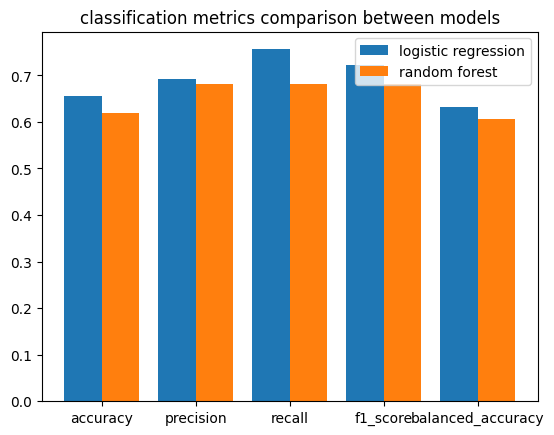

In [13]:
# plot comparison of key metrics between models
metric_names = ['accuracy', 'precision', 'recall', 'f1_score', 'balanced_accuracy']
lr_vals = [models_comparison.loc[0, m] for m in metric_names]
rf_vals = [models_comparison.loc[1, m] for m in metric_names]
x = np.arange(len(metric_names))

plt.bar(x - 0.2, lr_vals, width=0.4, label='logistic regression')
plt.bar(x + 0.2, rf_vals, width=0.4, label='random forest')
plt.xticks(x, metric_names)
plt.title('classification metrics comparison between models')
plt.legend()
plt.show()

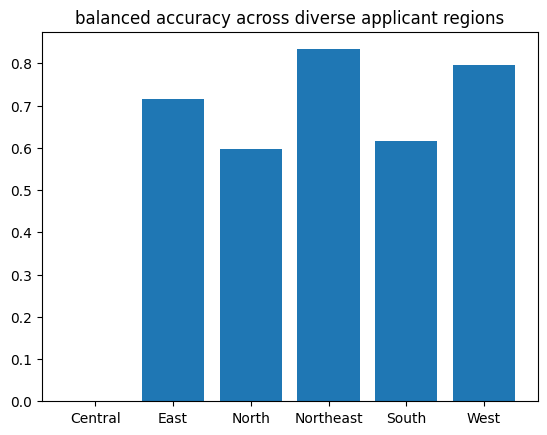

In [14]:
# plot balanced accuracy across applicant regions
plt.bar(region_metrics_df['region'], region_metrics_df['balanced_accuracy'])
plt.title('balanced accuracy across diverse applicant regions')
plt.show()

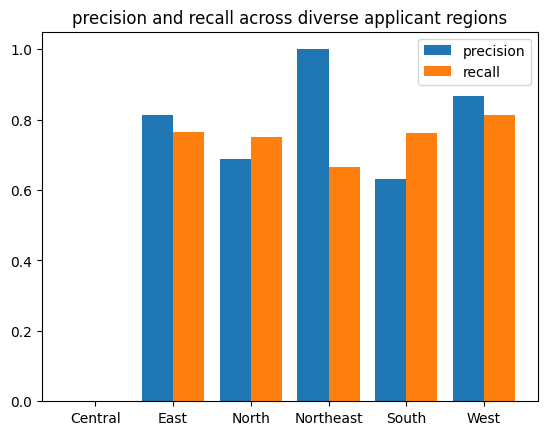

In [15]:
# plot precision and recall comparison across applicant regions
x_reg = np.arange(len(region_metrics_df))
plt.bar(x_reg - 0.2, region_metrics_df['precision'], width=0.4, label='precision')
plt.bar(x_reg + 0.2, region_metrics_df['recall'], width=0.4, label='recall')
plt.xticks(x_reg, region_metrics_df['region'])
plt.title('precision and recall across diverse applicant regions')
plt.legend()
plt.show()